# Praktikum Pembelajaran Mesin — Regresi Linear
**Program Studi Teknik Informatika S1**

Notebook ini mengikuti pokok materi Pertemuan 3: regresi linear sederhana dan berganda, koefisien/intercept, residual dan MSE, fitting model, evaluasi MAE–MSE–RMSE–R², pemeriksaan residual, outlier/leverage, multikolinearitas, interpretasi koefisien, serta perbandingan solusi `scikit-learn` dengan Normal Equation.

**Tujuan praktikum**
1. Membentuk model regresi linear dari data.
2. Memisahkan data latih dan data uji sebelum evaluasi.
3. Menghitung dan menafsirkan metrik regresi.
4. Memvisualisasikan garis regresi dan residual.
5. Mengamati pengaruh hubungan non-linear, outlier, dan multikolinearitas.
6. Menghitung koefisien dengan Normal Equation dan membandingkannya dengan model pustaka.

**Cara menjalankan:** buka notebook di Google Colab, lalu pilih *Runtime → Run all*. Sebagian besar contoh memakai data sintetis agar mudah dipahami dan hasilnya dapat direproduksi.

## 1. Persiapan pustaka

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.datasets import fetch_california_housing
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

SEED = 42
np.random.seed(SEED)
print("Pustaka siap digunakan.")

Pustaka siap digunakan.


## 2. Memahami data: jam belajar dan nilai ujian

Kita gunakan contoh sederhana yang sejalan dengan slide: satu fitur **jam belajar (X)** dan satu target **nilai ujian (Y)**. Data pertama sengaja dibuat kecil agar mudah diperiksa.

In [29]:
data_kecil = pd.DataFrame({
    "Nama": ["Andi", "Budi", "Cici"],
    "Jam_Belajar": [2, 4, 6],
    "Nilai_Ujian": [65, 75, 85]
})
display(data_kecil)

,Nama,Jam_Belajar,Nilai_Ujian
0,Andi,2,65
1,Budi,4,75
2,Cici,6,85


### Latihan singkat 1
Tanpa menjalankan model, menurut Anda apakah hubungan kedua variabel ini positif atau negatif? Apakah ketiga titik berada tepat pada satu garis?

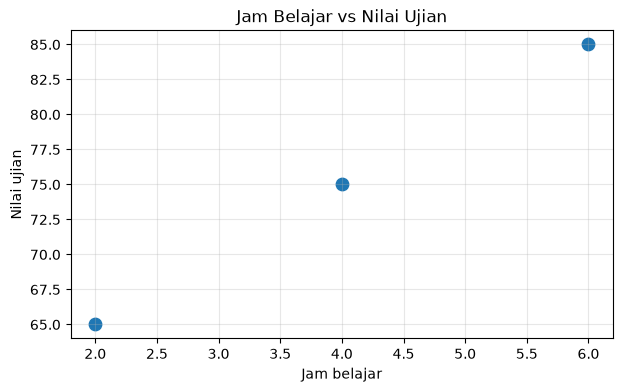

In [30]:
plt.figure(figsize=(7, 4))
plt.scatter(data_kecil["Jam_Belajar"], data_kecil["Nilai_Ujian"], s=80)
plt.xlabel("Jam belajar")
plt.ylabel("Nilai ujian")
plt.title("Jam Belajar vs Nilai Ujian")
plt.grid(alpha=0.3)
plt.show()

## 3. Fitting regresi linear sederhana

Model: \(\hat{y} = \beta_0 + \beta_1 x\)

- **Intercept** (β₀): prediksi target saat X = 0.
- **Koefisien/slope** (β₁): perubahan prediksi target untuk setiap kenaikan satu unit X.
- **Residual**: nilai aktual − nilai prediksi.

In [31]:
X = data_kecil[["Jam_Belajar"]]
y = data_kecil["Nilai_Ujian"]

model_kecil = LinearRegression()
model_kecil.fit(X, y)

print(f"Intercept (β0): {model_kecil.intercept_:.2f}")
print(f"Koefisien (β1): {model_kecil.coef_[0]:.2f}")
print(f"Persamaan: ŷ = {model_kecil.intercept_:.2f} + {model_kecil.coef_[0]:.2f}x")

data_kecil["Prediksi"] = model_kecil.predict(X)
data_kecil["Residual"] = data_kecil["Nilai_Ujian"] - data_kecil["Prediksi"]
display(data_kecil)

Intercept (β0): 55.00
Koefisien (β1): 5.00
Persamaan: ŷ = 55.00 + 5.00x


,Nama,Jam_Belajar,Nilai_Ujian,Prediksi,Residual
0,Andi,2,65,65.0,0.0
1,Budi,4,75,75.0,0.0
2,Cici,6,85,85.0,0.0


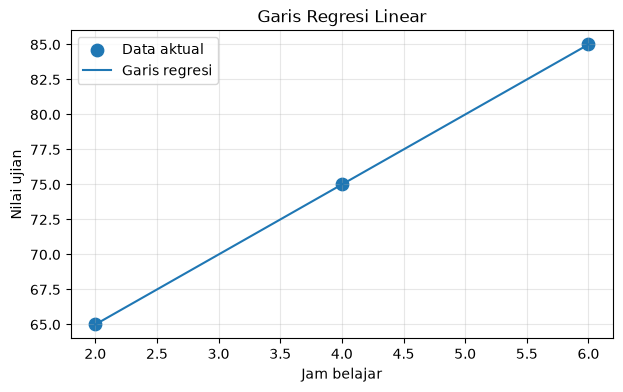

In [32]:
x_garis = np.linspace(data_kecil["Jam_Belajar"].min(), data_kecil["Jam_Belajar"].max(), 100)
y_garis = model_kecil.predict(pd.DataFrame({"Jam_Belajar": x_garis}))

plt.figure(figsize=(7, 4))
plt.scatter(data_kecil["Jam_Belajar"], data_kecil["Nilai_Ujian"], label="Data aktual", s=80)
plt.plot(x_garis, y_garis, label="Garis regresi")
plt.xlabel("Jam belajar")
plt.ylabel("Nilai ujian")
plt.title("Garis Regresi Linear")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Prediksi untuk data baru

Prediksi adalah estimasi model, bukan jaminan nilai sebenarnya. Hindari menafsirkan prediksi di luar rentang data latih secara berlebihan.

In [33]:
data_baru = pd.DataFrame({"Jam_Belajar": [3, 5, 7]})
data_baru["Prediksi_Nilai"] = model_kecil.predict(data_baru)
display(data_baru)

,Jam_Belajar,Prediksi_Nilai
0,3,70.0
1,5,80.0
2,7,90.0


## 4. Normal Equation: menghitung koefisien secara langsung

Untuk model linear dengan intercept, Normal Equation dapat ditulis:
\[
\beta = (X^T X)^{-1}X^T y
\]
Dalam praktik komputasi, `np.linalg.lstsq` lebih aman daripada menghitung invers secara eksplisit.

In [34]:
X_np = data_kecil[["Jam_Belajar"]].to_numpy()
y_np = data_kecil["Nilai_Ujian"].to_numpy()
X_design = np.column_stack([np.ones(len(X_np)), X_np])  # kolom 1 untuk intercept

beta, residuals, rank, singular_values = np.linalg.lstsq(X_design, y_np, rcond=None)
print("Normal Equation / least squares:")
print(f"β0 = {beta[0]:.2f}")
print(f"β1 = {beta[1]:.2f}")

print("\nPerbandingan dengan scikit-learn:")
print(f"Intercept sklearn = {model_kecil.intercept_:.2f}")
print(f"Koefisien sklearn = {model_kecil.coef_[0]:.2f}")

Normal Equation / least squares:
β0 = 55.00
β1 = 5.00

Perbandingan dengan scikit-learn:
Intercept sklearn = 55.00
Koefisien sklearn = 5.00


## 5. Loss dan metrik evaluasi: MSE, RMSE, MAE, dan R²

Agar evaluasi tidak hanya mengukur kemampuan model mengingat data, kita pisahkan data menjadi **train** dan **test**. Model hanya dilatih pada train; metrik akhir dihitung pada test.

In [35]:
# Membuat data sintetis yang memiliki sedikit variasi/noise
rng = np.random.default_rng(SEED)
n = 100
jam = rng.uniform(1, 10, n)
nilai = 50 + 4.5 * jam + rng.normal(0, 6, n)
df = pd.DataFrame({"Jam_Belajar": jam, "Nilai_Ujian": nilai})

X = df[["Jam_Belajar"]]
y = df["Nilai_Ujian"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Jumlah data train: {len(X_train)}")
print(f"Jumlah data test : {len(X_test)}")
print(f"MSE  = {mse:.3f}")
print(f"RMSE = {rmse:.3f} poin")
print(f"MAE  = {mae:.3f} poin")
print(f"R²   = {r2:.3f}")

Jumlah data train: 75
Jumlah data test : 25
MSE  = 26.395
RMSE = 5.138 poin
MAE  = 3.984 poin
R²   = 0.799


**Panduan interpretasi**
- MSE mengkuadratkan residual sehingga kesalahan besar mendapat penalti lebih besar.
- RMSE adalah akar MSE dan memakai satuan target (di sini poin nilai).
- MAE adalah rata-rata besar kesalahan absolut; relatif lebih tidak sensitif terhadap error ekstrem dibanding RMSE.
- R² mengukur performa relatif terhadap baseline rata-rata. R² dapat negatif pada data uji jika model lebih buruk daripada baseline tersebut.

Tidak ada ambang “baik” yang berlaku untuk semua kasus. Bandingkan metrik dengan konteks masalah dan baseline yang masuk akal.

In [36]:
hasil_uji = pd.DataFrame({
    "Aktual": y_test.to_numpy(),
    "Prediksi": y_pred,
})
hasil_uji["Residual (aktual - prediksi)"] = hasil_uji["Aktual"] - hasil_uji["Prediksi"]
display(hasil_uji.head(10))

,Aktual,Prediksi,Residual (aktual - prediksi)
0,62.578698,61.060492,1.518206
1,75.212537,82.068765,-6.856227
2,62.250852,63.069500,-0.818648
3,88.699225,87.972503,0.726722
4,75.414244,89.132690,-13.718446
5,86.656226,82.278187,4.378039
6,87.672285,94.974178,-7.301893
7,80.692868,82.046092,-1.353224
8,74.559169,69.661020,4.898148
9,88.243865,86.672527,1.571338


## 6. Plot prediksi dan residual

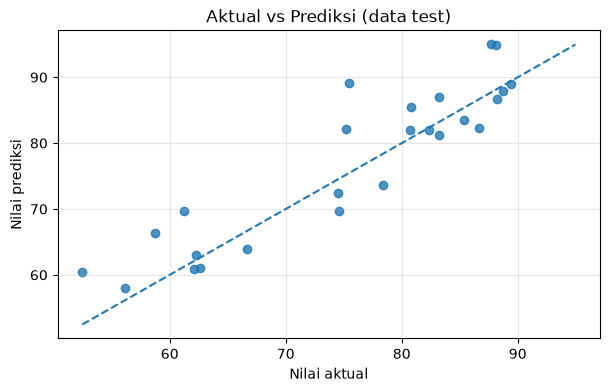

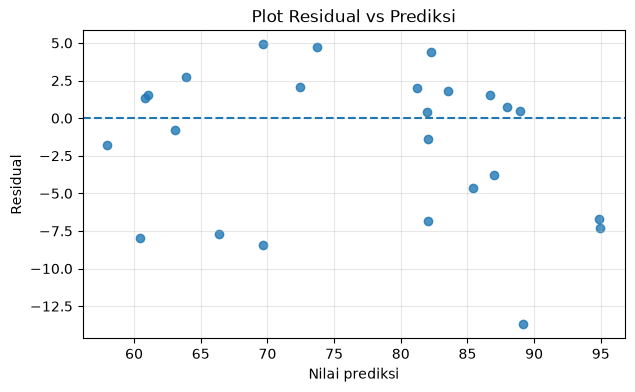

In [37]:
plt.figure(figsize=(7, 4))
plt.scatter(y_test, y_pred, alpha=0.8)
batas_min = min(y_test.min(), y_pred.min())
batas_maks = max(y_test.max(), y_pred.max())
plt.plot([batas_min, batas_maks], [batas_min, batas_maks], linestyle="--")
plt.xlabel("Nilai aktual")
plt.ylabel("Nilai prediksi")
plt.title("Aktual vs Prediksi (data test)")
plt.grid(alpha=0.3)
plt.show()

residual = y_test.to_numpy() - y_pred
plt.figure(figsize=(7, 4))
plt.scatter(y_pred, residual, alpha=0.8)
plt.axhline(0, linestyle="--")
plt.xlabel("Nilai prediksi")
plt.ylabel("Residual")
plt.title("Plot Residual vs Prediksi")
plt.grid(alpha=0.3)
plt.show()

**Pertanyaan interpretasi**
1. Apakah residual tersebar relatif acak di sekitar nol?
2. Apakah terlihat pola melengkung atau pola kipas?
3. Apa arti pola residual yang sistematis bagi asumsi linearitas atau variasi error?

Plot residual membantu diagnosis, tetapi tidak sendirian membuktikan semua asumsi model terpenuhi.

## 7. Hubungan non-linear: bandingkan model linear dan polynomial

Jika pola sebenarnya melengkung, garis lurus mungkin tidak cukup. Kita bandingkan model linear dengan regresi polynomial derajat 2. Polynomial regression tetap linear terhadap koefisien, tetapi memakai fitur seperti \(x^2\).

Linear                   | RMSE=9.17 | R²=0.924
Polynomial derajat 2     | RMSE=5.96 | R²=0.968


d:\KULIYAHHH\semester_5\20262027 Gasal - Pembelajaran Mesin - Nelly Indriani Widiastuti, M.T\Regresi Linier\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
d:\KULIYAHHH\semester_5\20262027 Gasal - Pembelajaran Mesin - Nelly Indriani Widiastuti, M.T\Regresi Linier\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


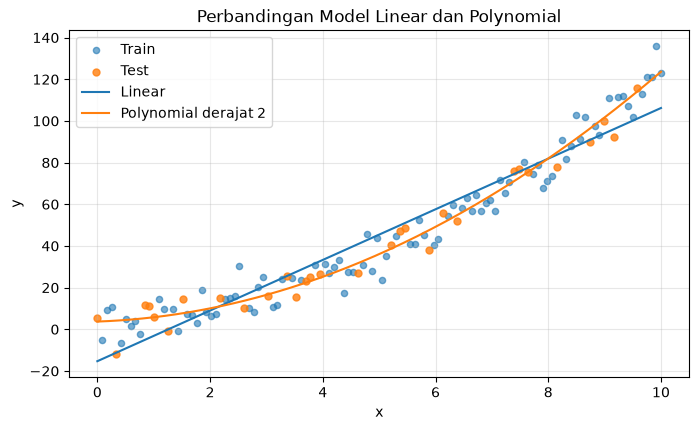

In [38]:
rng = np.random.default_rng(SEED)
x = np.linspace(0, 10, 120)
y_curve = 3 + 1.2*x + 1.1*(x**2) + rng.normal(0, 8, len(x))
df_curve = pd.DataFrame({"x": x, "y": y_curve})

Xtr, Xte, ytr, yte = train_test_split(
    df_curve[["x"]], df_curve["y"], test_size=0.25, random_state=SEED
)

linear = Pipeline([("model", LinearRegression())])
poly2 = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])
linear.fit(Xtr, ytr)
poly2.fit(Xtr, ytr)

for nama, mdl in [("Linear", linear), ("Polynomial derajat 2", poly2)]:
    pred = mdl.predict(Xte)
    print(f"{nama:24s} | RMSE={np.sqrt(mean_squared_error(yte, pred)):.2f} | R²={r2_score(yte, pred):.3f}")

x_plot = np.linspace(0, 10, 200).reshape(-1, 1)
plt.figure(figsize=(8, 4.5))
plt.scatter(Xtr["x"], ytr, s=20, alpha=0.6, label="Train")
plt.scatter(Xte["x"], yte, s=25, alpha=0.8, label="Test")
plt.plot(x_plot.ravel(), linear.predict(x_plot), label="Linear")
plt.plot(x_plot.ravel(), poly2.predict(x_plot), label="Polynomial derajat 2")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Perbandingan Model Linear dan Polynomial")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Diskusi:** model mana yang memperoleh RMSE test lebih rendah? Apakah kompleksitas lebih tinggi selalu lebih baik? Jelaskan berdasarkan hasil, bukan hanya berdasarkan bentuk garis.

## 8. Dampak outlier pada target

Satu nilai target ekstrem dapat menarik garis regresi dan memperbesar MSE/RMSE. Pada contoh ini kita bandingkan model dengan dan tanpa satu titik ekstrem. Jangan otomatis menghapus outlier: periksa apakah data salah, kejadian nyata, atau bagian penting dari populasi.

Tanpa outlier: intercept=39.10, slope=3.08
Dengan outlier: intercept=37.59, slope=3.29


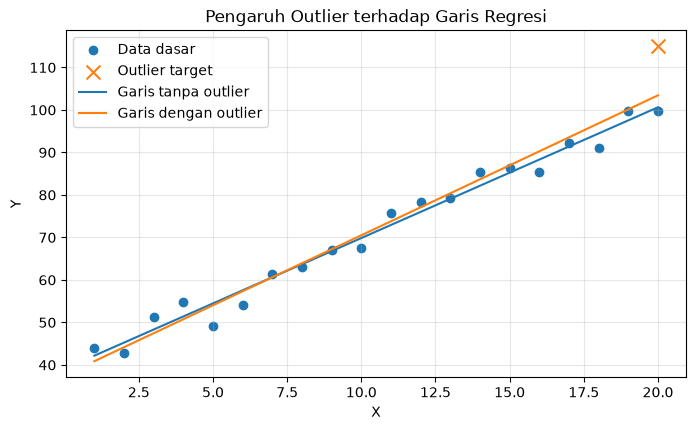

In [39]:
rng = np.random.default_rng(SEED)
x = np.arange(1, 21, dtype=float)
y = 40 + 3*x + rng.normal(0, 3, len(x))
y_outlier = y.copy()
y_outlier[-1] = 115  # satu target ekstrem untuk demonstrasi

m_normal = LinearRegression().fit(x.reshape(-1, 1), y)
m_out = LinearRegression().fit(x.reshape(-1, 1), y_outlier)

print(f"Tanpa outlier: intercept={m_normal.intercept_:.2f}, slope={m_normal.coef_[0]:.2f}")
print(f"Dengan outlier: intercept={m_out.intercept_:.2f}, slope={m_out.coef_[0]:.2f}")

xx = np.linspace(1, 20, 100).reshape(-1, 1)
plt.figure(figsize=(8, 4.5))
plt.scatter(x, y, label="Data dasar")
plt.scatter([x[-1]], [y_outlier[-1]], label="Outlier target", marker="x", s=100)
plt.plot(xx, m_normal.predict(xx), label="Garis tanpa outlier")
plt.plot(xx, m_out.predict(xx), label="Garis dengan outlier")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Pengaruh Outlier terhadap Garis Regresi")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Catatan tentang leverage
Leverage berkaitan dengan posisi ekstrem pada fitur X; titik seperti ini dapat berpengaruh besar pada garis regresi. Di analisis regresi yang lebih mendalam, hat values dan Cook's distance dapat membantu mengidentifikasi observasi yang berpengaruh. Praktikum ini baru mengilustrasikan pengaruh titik ekstrem secara visual.

## 9. Regresi linear berganda dan multikolinearitas

Regresi berganda memakai lebih dari satu fitur, misalnya jam belajar dan kehadiran untuk memprediksi nilai. Koefisien diinterpretasikan sebagai perubahan prediksi ketika satu fitur naik satu unit **dengan fitur lain dianggap tetap**.

In [40]:
rng = np.random.default_rng(SEED)
n = 160
jam = rng.uniform(1, 10, n)
kehadiran = rng.uniform(60, 100, n)
nilai = 35 + 4.2*jam + 0.25*kehadiran + rng.normal(0, 5, n)

df_multi = pd.DataFrame({
    "Jam_Belajar": jam,
    "Kehadiran": kehadiran,
    "Nilai_Ujian": nilai
})
X = df_multi[["Jam_Belajar", "Kehadiran"]]
y = df_multi["Nilai_Ujian"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED)

multi = LinearRegression().fit(Xtr, ytr)
pred = multi.predict(Xte)
print(f"Intercept: {multi.intercept_:.3f}")
for fitur, koef in zip(X.columns, multi.coef_):
    print(f"Koefisien {fitur}: {koef:.3f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(yte, pred)):.3f}")
print(f"Test R²  : {r2_score(yte, pred):.3f}")

Intercept: 31.492
Koefisien Jam_Belajar: 4.326
Koefisien Kehadiran: 0.289
Test RMSE: 4.675
Test R²  : 0.846


### Demonstrasi multikolinearitas
Buat fitur kedua yang hampir merupakan salinan linear dari fitur pertama. Prediksi bisa tetap cukup baik, tetapi koefisien individual dapat menjadi tidak stabil atau sulit diinterpretasikan.

In [41]:
rng = np.random.default_rng(SEED)
n = 150
x1 = rng.normal(50, 10, n)
x2 = 2*x1 + rng.normal(0, 0.5, n)  # sangat berkorelasi dengan x1
y = 10 + 1.5*x1 + rng.normal(0, 5, n)

X_corr = pd.DataFrame({"Fitur_A": x1, "Fitur_B_hampir_duplikat": x2})
print("Korelasi antarf fitur:")
display(X_corr.corr())

Xtr, Xte, ytr, yte = train_test_split(X_corr, y, test_size=0.25, random_state=SEED)
mdl_corr = LinearRegression().fit(Xtr, ytr)
print("Koefisien:", dict(zip(X_corr.columns, mdl_corr.coef_)))
print("Test R²:", round(r2_score(yte, mdl_corr.predict(Xte)), 3))
print("Catatan: jangan menyimpulkan pentingnya fitur hanya dari besar koefisien ketika fitur sangat berkorelasi.")

Korelasi antarf fitur:


,Fitur_A,Fitur_B_hampir_duplikat
Fitur_A,1.000000,0.999575
Fitur_B_hampir_duplikat,0.999575,1.000000


Koefisien: {'Fitur_A': np.float64(5.27852543399463), 'Fitur_B_hampir_duplikat': np.float64(-1.8991440882764408)}
Test R²: 0.827
Catatan: jangan menyimpulkan pentingnya fitur hanya dari besar koefisien ketika fitur sangat berkorelasi.


## 10. Interpretasi koefisien dan skala fitur

Tanda koefisien menunjukkan arah hubungan yang dipelajari model, tetapi tidak otomatis membuktikan sebab-akibat. Besar koefisien antarfitur tidak bisa dibandingkan langsung jika skala/satuan fiturnya berbeda. Standardisasi dapat membantu perbandingan skala, khususnya untuk model yang sensitif terhadap skala.

In [42]:
# Contoh ringkas: standardisasi hanya pada fitur, dengan pipeline agar transformasi konsisten
pipe_std = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
pipe_std.fit(Xtr, ytr)
print("Koefisien pada fitur terstandardisasi:", pipe_std.named_steps["model"].coef_)

Koefisien pada fitur terstandardisasi: [ 45.82198361 -32.99734249]


## 11. Eksplorasi dataset nyata: California Housing (opsional)

Bagian ini mencoba dataset California Housing dari scikit-learn. Dataset mungkin perlu diunduh saat pertama kali dijalankan dan memerlukan koneksi internet. Jika gagal, lewati bagian ini; bagian sebelumnya tetap dapat digunakan.

In [43]:
try:
    housing = fetch_california_housing(as_frame=True)
    Xh = housing.data
    yh = housing.target

    X_train, X_test, y_train, y_test = train_test_split(
        Xh, yh, test_size=0.2, random_state=SEED
    )
    housing_model = LinearRegression()
    housing_model.fit(X_train, y_train)
    yh_pred = housing_model.predict(X_test)

    print(f"Jumlah fitur: {Xh.shape[1]}")
    print(f"RMSE test: {np.sqrt(mean_squared_error(y_test, yh_pred)):.3f}")
    print(f"MAE test : {mean_absolute_error(y_test, yh_pred):.3f}")
    print(f"R² test  : {r2_score(y_test, yh_pred):.3f}")

    coef_table = pd.DataFrame({
        "Fitur": Xh.columns,
        "Koefisien": housing_model.coef_
    })
    coef_table["Nilai_absolut"] = coef_table["Koefisien"].abs()
    display(coef_table.sort_values("Nilai_absolut", ascending=False))
except Exception as e:
    print("Dataset opsional tidak berhasil dimuat.")
    print("Silakan lewati bagian ini atau periksa koneksi internet.")
    print("Pesan teknis:", repr(e))

Jumlah fitur: 8
RMSE test: 0.746
MAE test : 0.533
R² test  : 0.576


,Fitur,Koefisien,Nilai_absolut
3,AveBedrms,0.783145,0.783145
0,MedInc,0.448675,0.448675
7,Longitude,-0.433708,0.433708
6,Latitude,-0.419792,0.419792
2,AveRooms,-0.123323,0.123323
1,HouseAge,0.009724,0.009724
5,AveOccup,-0.003526,0.003526
4,Population,-0.000002,0.000002


## 12. Tugas praktikum mahasiswa

Kerjakan dan kumpulkan notebook yang telah dilengkapi jawaban/komentar pada sel Markdown.

### Tugas A — Eksperimen model
1. Ubah `test_size` menjadi 0.20 lalu 0.30. Catat RMSE, MAE, dan R².
2. Jalankan ulang dengan `random_state=7`. Apakah metrik berubah? Jelaskan.
3. Bandingkan koefisien dan intercept untuk setiap percobaan.

### Tugas B — Diagnostik
4. Amati plot residual model pada Bagian 6. Jelaskan apakah terlihat pola sistematis.
5. Pada Bagian 7, bandingkan model linear dan polynomial berdasarkan metrik data test.
6. Pada Bagian 8, jelaskan perubahan slope ketika outlier ditambahkan.

### Tugas C — Interpretasi
7. Jelaskan makna intercept dan koefisien pada regresi berganda Bagian 9.
8. Mengapa multikolinearitas menyulitkan interpretasi koefisien?
9. Jelaskan perbedaan MAE dan RMSE serta kapan masing-masing berguna.
10. Tulis 1–2 paragraf insight berdasarkan hasil eksperimen, bukan hanya menyalin angka.

### Format laporan
- Tujuan eksperimen.
- Langkah dan perubahan parameter.
- Tabel metrik train/test bila relevan.
- Minimal satu plot.
- Kesimpulan dan keterbatasan.

**Pengingat:** jangan memilih model hanya dari performa training. Gunakan data test untuk menilai kemampuan generalisasi.

### Tugas A — Eksperimen model

In [44]:
X_data = df[['Jam_Belajar']]
y_data = df['Nilai_Ujian']
percobaan = [
    ('test_size=0.20, seed=42', 0.20, 42),
    ('test_size=0.30, seed=42', 0.30, 42),
    ('test_size=0.20, seed=7', 0.20, 7),
    ('test_size=0.30, seed=7', 0.30, 7),
]
hasil = []
for label, ts, rs in percobaan:
  X_tr, X_te, y_tr, y_te = train_test_split(
      X_data, y_data, test_size=ts, random_state=rs
  )
  mdl = LinearRegression()
  mdl.fit(X_tr, y_tr)
  y_pred = mdl.predict(X_te)
  b0 = round(mdl.intercept_, 3)
  b1 = round(mdl.coef_[0], 3)
  hasil.append({
      'Percobaan': label,
      'test_size': ts,
      'random_state': rs,
      'Intercept (β0)': b0,
      'Koefisien (β1)': b1,
      'Persamaan Garis': f'ŷ = {b0} + {b1}x',
      'RMSE': round(np.sqrt(mean_squared_error(y_te, y_pred)), 3),
      'MAE': round(mean_absolute_error(y_te, y_pred), 3),
      'R²': round(r2_score(y_te, y_pred), 3),
  })
df_hasil = pd.DataFrame(hasil)
display(df_hasil)

,Percobaan,test_size,random_state,Intercept (β0),Koefisien (β1),Persamaan Garis,RMSE,MAE,R²
0,"test_size=0.20, seed=42",0.2,42,49.529,4.664,ŷ = 49.529 + 4.664x,5.560,4.308,0.789
1,"test_size=0.30, seed=42",0.3,42,49.543,4.676,ŷ = 49.543 + 4.676x,5.660,4.472,0.762
2,"test_size=0.20, seed=7",0.2,7,49.513,4.508,ŷ = 49.513 + 4.508x,6.259,4.911,0.695
3,"test_size=0.30, seed=7",0.3,7,49.547,4.504,ŷ = 49.547 + 4.504x,5.761,4.658,0.827


1. Hasilnya ada di tabel di atas.

2. metrik berubah setelah random_state diganti jadi 7. Pas test_size=0.20, RMSE naik dari 5.560 jadi 6.259, MAE naik dari 4.308 jadi 4.911, dan R² turun dari 0.789 jadi 0.695, jadi performa modelnya menurun. Pas test_size=0.3, RMSE naik dikit dari 5.660 jadi 5.761 dan MAE naik dari 4.472 jadi 4.658, tapi R² malah naik dari 0.762 jadi 0.827. Jadi perubahannya nggak selalu searah, tapi angka ketiga metrik itu jelas beda dari sebelumnya.
Metriknya berubah karena random_state ngatur baris data mana yang masuk ke data train dan data test. Kalau seed-nya beda, isi data test-nya juga beda, bisa lebih gampang atau lebih susah ditebak, jadi error dan R² ikut bergeser. Jadi ini bukan karena modelnya salah, tapi karena sampel datanya beda. Artinya hasil dari sekali pembagian data belum tentu stabil.


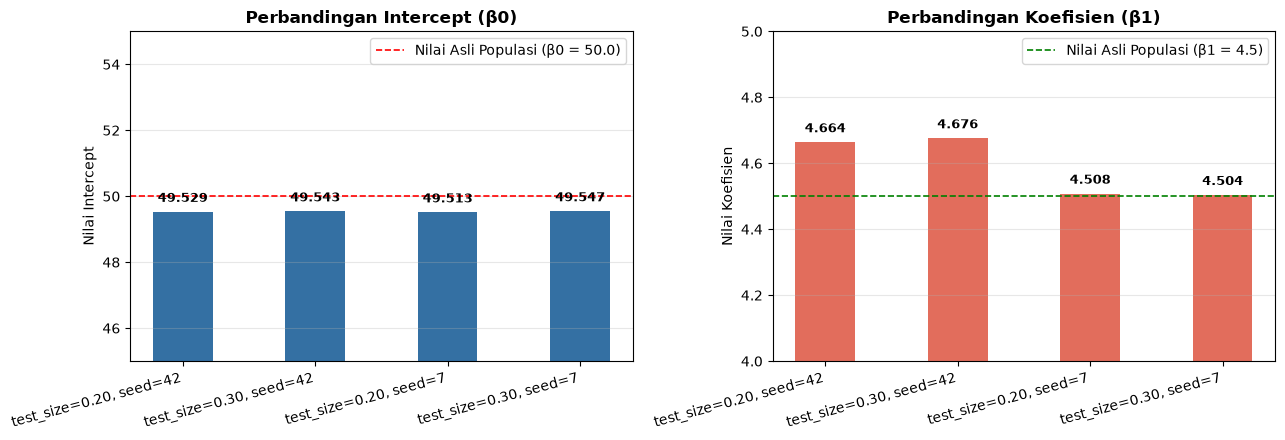

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
x_pos = np.arange(len(df_hasil))
# 1. Bar Chart Intercept (β0)
ax[0].bar(x_pos, df_hasil['Intercept (β0)'], color='#3470a3', width=0.45)
ax[0].axhline(
    50.0,
    color='red',
    linestyle='--',
    linewidth=1.2,
    label='Nilai Asli Populasi (β0 = 50.0)',
)
ax[0].set_title('Perbandingan Intercept (β0)', fontweight='bold')
ax[0].set_ylabel('Nilai Intercept')
ax[0].set_ylim(45, 55)
ax[0].set_xticks(x_pos)
ax[0].set_xticklabels(df_hasil['Percobaan'], rotation=15, ha='right')
ax[0].legend()
ax[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(df_hasil['Intercept (β0)']):
  ax[0].text(i, v + 0.3, str(v), ha='center', fontweight='bold', fontsize=9)
# 2. Bar Chart Koefisien (β1)
ax[1].bar(x_pos, df_hasil['Koefisien (β1)'], color='#e26d5c', width=0.45)
ax[1].axhline(
    4.5,
    color='green',
    linestyle='--',
    linewidth=1.2,
    label='Nilai Asli Populasi (β1 = 4.5)',
)
ax[1].set_title('Perbandingan Koefisien (β1)', fontweight='bold')
ax[1].set_ylabel('Nilai Koefisien')
ax[1].set_ylim(4.0, 5.0)
ax[1].set_xticks(x_pos)
ax[1].set_xticklabels(df_hasil['Percobaan'], rotation=15, ha='right')
ax[1].legend()
ax[1].grid(axis='y', alpha=0.3)
for i, v in enumerate(df_hasil['Koefisien (β1)']):
  ax[1].text(i, v + 0.03, str(v), ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()


3. Intercept dan koefisien di keempat percobaan angkanya hampir sama. Intercept berkisar 49.513 sampai 49.547, dan koefisien berkisar 4.504 sampai 4.676. Jadi modelnya stabil, sekitar ŷ ≈ 49.5 + 4.6x. Ganti test_size hampir nggak ngubah koefisien, tapi ganti random_state dari 42 ke 7 bikin koefisien turun dari sekitar 4.67 jadi sekitar 4.51, karena data train-nya beda. Kalau dibanding nilai asli populasi (β0 = 50.0 dan β1 = 4.5), semua percobaan cukup dekat, dan koefisien seed 7 paling mendekati 4.5.

### Tugas B — Diagnostik
4. Di plot residual, titiknya nyebar acak di sekitar garis 0 dan gak ngembentuk lengkungan atau corong. Jadi nggak ada pola sistematis, model linear udah cukup cocok buat data nya. Cuma ada beberapa titik dengan residual negatif yang agak besar (paling jauh sekitar -13.5) di prediksi tinggi, tapi itu kelihatannya titik yang menyimpang, bukan pola.

5. 5. Pada Bagian 7, model polynomial derajat 2 lebih bagus daripada model linear di semua metrik data test. RMSE turun sekitar 35% dari 9.171 jadi 5.964, MAE turun dari 7.166 jadi 4.797, dan R² naik dari 0.924 jadi 0.968, artinya polynomial bisa ngejelasin 96.8% variasi data test, sedangkan linear cuma 92.4%. Jadi rata-rata kesalahan prediksi polynomial jauh lebih kecil.

Penyebabnya, data di Bagian 7 dibuat dari fungsi kuadratik (y = 3 + 1.2x + 1.1x²), bukan fungsi linear. Garis lurus nggak cukup fleksibel buat ngikutin pola yang melengkung ini, jadi terjadi underfitting. Model polynomial derajat 2 bisa nangkep pola kurva itu karena bentuknya memang cocok sama data. Karena perbandingannya pakai data test, kelihatan kalau polynomial memang lebih bagus buat generalisasi, bukan cuma bagus di data latih.

6. Pas outlier ekstrem (y = 115 pada x = 20) ditambahkan, slope naik dari 3.076 jadi 3.293 (naik 0.217), dan intercept turun dari 39.102 jadi 37.587. Garis regresinya jadi lebih miring karena ketarik ke arah outlier. Ini terjadi karena regresi linear ngeminimalin kuadrat error, jadi titik yang jauh punya pengaruh besar, apalagi posisinya di ujung kanan data (x = 20). Jadi regresi linear sensitif sama outlier.


### Tugas C — Interpretasi
7. Di Bagian 9, regresi berganda nya pakai dua fitur, Jam_Belajar dan Kehadiran, buat nebak Nilai_Ujian.

- **Intercept (31.492)**: nilai ujian yang ditebak model kalau Jam_Belajar = 0 dan Kehadiran = 0%. Sebenernya ga terlalu bermakna, soalnya kehadiran 0% ga ada di data . Jadi cuma jadi titik awal model aja.
- **Koefisien Jam_Belajar (4.326)**: tiap nambah 1 jam belajar, nilai ujian naik sekitar 4.326 poin, kalau Kehadiran-nya sama.
- **Koefisien Kehadiran (0.289)**: tiap naik 1% kehadiran, nilai ujian naik sekitar 0.289 poin, kalau Jam_Belajar-nya sama.

Jadi di regresi berganda, pengaruh tiap fitur dilihat sendiri-sendiri, dengan fitur lainnya dianggap ga berubah. Tandanya positif, artinya makin gede fiturnya makin gede nilainya. Tapi ini ga membuktikan sebab-akibat, dan angka koefisiennya ga bisa langsung dibandingin kalau satuannya beda. Modelnya juga lumayan bagus di data test , artinya dua fitur itu bisa jelasin sekitar 84.6% variasi nilai ujian.

8. Multikolinearitas bikin koefisien susah diinterpretasi karena dua fitur atau lebih saling berkorelasi tinggi. Di Bagian 9, Fitur_A dan Fitur_B_hampir_duplikat dibuat hampir identik (korelasi 0.9996). Hasilnya koefisiennya aneh Fitur_A = +5.279 dan Fitur_B = −1.899, padahal data aslinya cuma dibuat dari x1 dengan koefisien 1.5.

Masalahnya ada tiga:
- Pengaruh tiap fitur nggak bisa dipisahin. Koefisien itu artinya "pengaruh satu fitur kalau fitur lain tetap", tapi kalau dua fitur selalu naik turun bareng, model nggak bisa misahin pengaruhnya. Akhirnya muncul kombinasi koefisien yang aneh (satu gede positif, satu negatif) yang secara hitungan bener tapi ga masuk akal.
- Koefisiennya nggak stabil. Data latih berubah dikit aja, koefisiennya bisa beda jauh, padahal prediksinya tetap bagus (R² = 0.827). Jadi modelnya kelihatan akurat, tapi interpretasinya menyesatkan.
- Nggak bisa nentuin fitur mana yang lebih penting. saya nggak bisa bilang Fitur_A lebih penting dari Fitur_B cuma dari besar koefisiennya, karena keduanya saling ganggu.

9. MAE dan RMSE sama-sama ngukur seberapa besar kesalahan prediksi dan satuannya sama dengan target. Bedanya ada di cara ngitung error besar. MAE ngitung rata-rata selisih absolut, jadi semua error dihitung sama (linear). RMSE ngitung akar dari rata-rata kuadrat selisih, jadi error besar dihukum lebih berat. Karena itu RMSE lebih sensitif sama outlier, sedangkan MAE lebih tahan. RMSE juga selalu sama atau lebih besar dari MAE.

- **MAE berguna** kalau outlier itu hal yang wajar dan nggak mau dikasih hukuman berlebihan, atau kalau pengen ngukur rata-rata kesalahan secara adil. Contohnya prediksi waktu pengiriman paket, karena keterlambatan besar bisa terjadi gara-gara faktor luar biasa.
- **RMSE berguna** kalau error besar itu sangat nggak diinginkan dan harus dihukum lebih keras. Contohnya prediksi harga rumah atau dosis obat, karena kesalahan besar bisa berdampak fatal.
10. Tulis 1–2 paragraf insight berdasarkan hasil eksperimen, bukan hanya menyalin angka.

10. Dari semua eksperimen di praktikum ini, kelihatan kalau bagus nggaknya model regresi linear itu tergantung cocok nggaknya model sama pola asli datanya. Pas hubungan datanya memang linear (Bagian 5 dan 6), model linear jalan bagus, dengan R² sekitar 0.80 dan residual yang nyebar acak. Tapi pas pola datanya kuadratik (Bagian 7), model linear jadi underfitting dengan RMSE 9.17, sedangkan polynomial derajat 2 bisa nurunin RMSE jadi 5.96. Jadi milih model yang cocok sama bentuk data itu lebih penting daripada cuma nambah data. Di Tugas A juga kelihatan kalau ganti random_state bikin metrik test berubah, sedangkan koefisiennya relatif stabil, jadi hasil dari sekali pembagian data belum tentu bisa dipercaya sepenuhnya.

Selain itu, Bagian 8 dan 9 nunjukin dua kelemahan regresi. Pertama, satu outlier aja bisa nggeser slope dari 3.08 jadi 3.29 karena OLS ngitung error secara kuadrat. Kedua, dua fitur yang hampir sama (multikolinearitas) bikin koefisiennya jadi nggak masuk akal (+5.28 dan −1.90), padahal prediksinya masih bagus (R² = 0.827). Jadi pelajaran utamanya, metrik yang bagus belum tentu berarti model dan koefisiennya bisa dipercaya. Kita juga perlu ngecek asumsi, plot residual, dan hubungan antar fitur sebelum narik kesimpulan, dan milih model berdasarkan performa data test, bukan data training.


## 13. Rubrik penilaian yang disarankan

| Komponen | Bobot |
|---|---:|
| Kode berjalan dan eksperimen dapat direproduksi | 20% |
| Pemisahan data dan evaluasi metrik dengan benar | 20% |
| Visualisasi dan analisis residual/outlier | 20% |
| Interpretasi koefisien dan multikolinearitas | 20% |
| Insight, kesimpulan, dan kerapian laporan | 20% |

**Selesai.** Pastikan semua sel kode berhasil dijalankan dan jawaban analisis ditulis dengan kata-kata sendiri.